# Evaluation

Milestone 2 starts this notebook with **check 3**: a chart of Elo ratings since 2000. Milestone 3 adds the model evaluation, further down.

The chart shows the Premier League rating before each game for the clubs that spent the most seasons in the league. Each panel highlights one club and shows the others in grey for context. Thin vertical lines mark season starts.

**What to look for:** sudden jumps in mid-season or flat stretches would point to bugs. Small steps at season starts are expected, because the summer shrink pulls every rating part of the way to 1500.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "backend"))
from elo import Elo, run_elo
from load_data import load_matches

matches = load_matches()
elo = Elo.from_settings()
ratings = run_elo(matches, elo)
print(f"Elo settings: K={elo.k}, s={elo.s}, a={elo.a}, N_home={elo.n_home}")

Elo settings: K=12.5, s=0.1, a=0.25, N_home=380


In [2]:
pl = matches["league"] == "E0"
games = pd.concat([
    pd.DataFrame({"date": matches.loc[pl, "date"], "season": matches.loc[pl, "season"],
                  "team": matches.loc[pl, side + "_team"], "rating": ratings.loc[pl, side + "_elo"]})
    for side in ("home", "away")
]).sort_values("date")

seasons_in_pl = games.groupby("team")["season"].nunique().sort_values(ascending=False)
clubs = list(seasons_in_pl.index[:6])
season_starts = games.groupby("season")["date"].min()
print("Seasons in the Premier League:", seasons_in_pl[clubs].to_dict())

def club_line(team):
    """Dates and ratings, with a break wherever the club left the league."""
    g = games[games["team"] == team].set_index("date")["rating"]
    gaps = g.index.to_series().diff() > pd.Timedelta(days=150)
    for when in g.index[gaps]:
        g.loc[when - pd.Timedelta(days=1)] = float("nan")
    return g.sort_index()

Seasons in the Premier League: {'Arsenal': 27, 'Tottenham': 27, 'Man United': 27, 'Liverpool': 27, 'Chelsea': 27, 'Everton': 27}


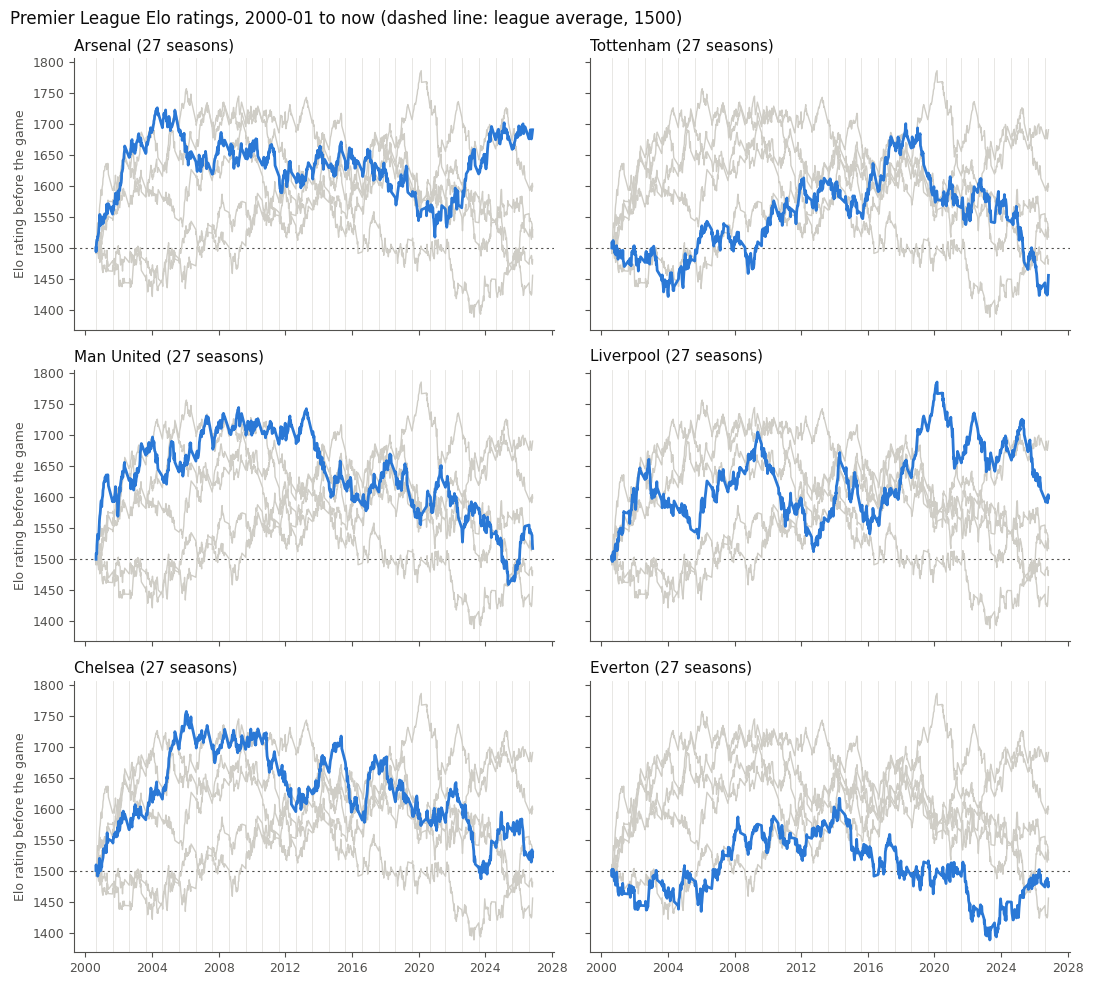

In [3]:
INK, MUTED, RULE, CONTEXT, HIGHLIGHT = "#0b0b0b", "#52514e", "#e4e3df", "#cfcdc6", "#2a78d6"
lines = {team: club_line(team) for team in clubs}

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True, sharey=True)
for ax, team in zip(axes.flat, clubs):
    for start in season_starts:
        ax.axvline(start, color=RULE, linewidth=0.6, zorder=0)
    ax.axhline(1500, color=MUTED, linewidth=0.8, linestyle=(0, (2, 3)), zorder=1)
    for other in clubs:
        if other != team:
            ax.plot(lines[other].index, lines[other].values, color=CONTEXT, linewidth=1, zorder=2)
    ax.plot(lines[team].index, lines[team].values, color=HIGHLIGHT, linewidth=2, zorder=3)
    ax.set_title(f"{team} ({seasons_in_pl[team]} seasons)", loc="left", fontsize=11, color=INK)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Elo rating before the game", color=MUTED, fontsize=9)
fig.suptitle("Premier League Elo ratings, 2000-01 to now (dashed line: league average, 1500)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
plt.show()

The same numbers as a table: each club's rating at the start of every fifth season.

In [4]:
start = pd.DataFrame({season: pd.Series(elo.season_start[("E0", season)])
                      for (league, season) in elo.season_start if league == "E0"})
start.reindex(clubs)[start.columns[::5]].round(0)

,2000-01,2005-06,2010-11,2015-16,2020-21,2025-26
Arsenal,1500.0,1687.0,1633.0,1641.0,1559.0,1659.0
Tottenham,1500.0,1479.0,1553.0,1556.0,1576.0,1465.0
Man United,1500.0,1641.0,1702.0,1613.0,1600.0,1469.0
Liverpool,1500.0,1544.0,1616.0,1577.0,1725.0,1673.0
Chelsea,1500.0,1696.0,1704.0,1675.0,1574.0,1565.0
Everton,1500.0,1482.0,1576.0,1521.0,1479.0,1478.0


## Milestone 3: the model on the test seasons

The model is a softmax logistic regression. Its settings were tuned on the validation seasons, 2015-16 to 2018-19, and saved in `backend/model_settings.json`. That file was committed before any test season was scored.

The test is **walk-forward**. To predict 2022-23, for example, the model trains on every season from 2002-03 to 2021-22. So every game here is predicted by a model that had never seen it. The baselines are trained the same way.

The table covers all seven test seasons together: 2,660 games. Log loss is the main score, and lower is better.

In [5]:
# This section runs on its own: it sets up its own imports and colors.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "backend"))
from evaluate import NAMES, compare
from train import OUTCOMES, TEST, load_settings, load_table, model_features, train_final, weights

INK, MUTED, RULE = "#0b0b0b", "#52514e", "#e4e3df"
settings = load_settings()
table = load_table()
result = compare(table, TEST, settings)
rows, scores, probs = result["rows"], result["scores"], result["probs"]
print(f"Settings: elastic net (l1_ratio {settings['l1_ratio']}), C {settings['c']}, "
      f"{len(settings['features'])} features, Premier League rows only")

summary = pd.DataFrame({NAMES.get(n, "Always home"): r for n, r in result["overall"].items()}).T
summary[["log_loss", "accuracy", "brier"]].round(4)

Settings: elastic net (l1_ratio 0.5), C 0.0316, 29 features, Premier League rows only


,log_loss,accuracy,brier
Model,0.983309,0.527068,0.584879
Elo only,0.989609,0.524812,0.588745
Average shares,1.072906,0.434211,0.649681
Bookmakers,0.967662,0.544737,0.574465
Always home,NaN,0.434211,NaN


### How far behind the bookmakers, season by season

Each point is a season's average log loss **minus the bookmakers'**. The line at 0 is the bookmakers, and lower is better. The bars show ±1 standard error of the per-game differences.

**What to look for:** the model should sit between Elo only and the bookmakers. 2020-21 stands out. That season was played without crowds, and the next section shows what that did to home wins.

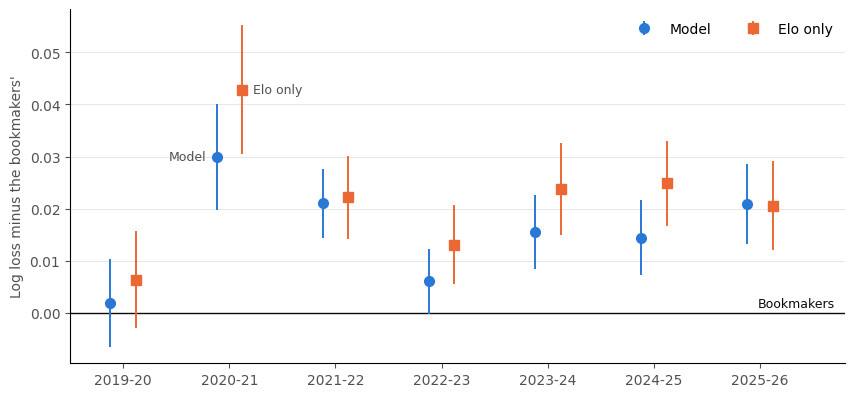

In [6]:
SERIES = {"model": ("Model", "#2a78d6", "o", -0.12), "elo_only": ("Elo only", "#eb6834", "s", 0.12)}
x = np.arange(len(TEST))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.set_axisbelow(True)
ax.axhline(0, color=INK, linewidth=1, zorder=2)
ax.text(len(TEST) - 0.3, 0.0006, "Bookmakers", color=INK, fontsize=9, va="bottom", ha="right")
for name, (label, color, marker, shift) in SERIES.items():
    d = scores[name]["log_loss"] - scores["bookmakers"]["log_loss"]
    by_season = d.groupby(rows["season"])
    mean = by_season.mean()[TEST]
    se = (by_season.std() / np.sqrt(by_season.size()))[TEST]
    ax.errorbar(x + shift, mean, yerr=se, fmt=marker, color=color, ms=7, elinewidth=1.4,
                capsize=0, label=label, zorder=3)
    # direct labels beside 2020-21, where the two series are furthest apart
    side = -1 if shift < 0 else 1
    ax.text(x[1] + shift + side * 0.1, mean.iloc[1], label, color=MUTED, fontsize=9,
            va="center", ha="right" if side < 0 else "left")
ax.set_xticks(x, TEST)
ax.set_xlim(-0.5, len(TEST) - 0.2)
ax.set_ylabel("Log loss minus the bookmakers'", color=MUTED)
ax.grid(axis="y", color=RULE, linewidth=0.6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()

### Home wins without crowds

This table compares each season's actual home-win share with the average home-win probability the model and the bookmakers gave. In 2020-21, with empty stadiums, home teams won only about 38% of games. The model still expected about 46%, because nothing in its inputs says whether fans are in the ground. The bookmakers adjusted part of the way.

In [7]:
home = pd.DataFrame({"season": rows["season"], "home wins": rows["result"].eq("H"),
                     "model said": probs["model"][:, 0], "bookmakers said": probs["bookmakers"][:, 0]})
home.groupby("season").mean().round(3)

,home wins,model said,bookmakers said
season,,,
2019-20,0.453,0.461,0.439
2020-21,0.379,0.461,0.418
2021-22,0.429,0.439,0.433
2022-23,0.484,0.448,0.438
2023-24,0.461,0.454,0.448
2024-25,0.408,0.453,0.448
2025-26,0.426,0.446,0.437


### Calibration

When the model says 60%, does it happen about 60% of the time? Each point groups the test games by the model's probability for that outcome, in 10-point bins with at least 20 games. The dashed line is perfect calibration, and the bars show ±1 standard error.

**What to look for:** points within about two standard errors of the line. Home wins at 40–60% happen a little less often than predicted, and away wins a little more often. That fits the home-advantage table above: the test seasons had fewer home wins than the training seasons.

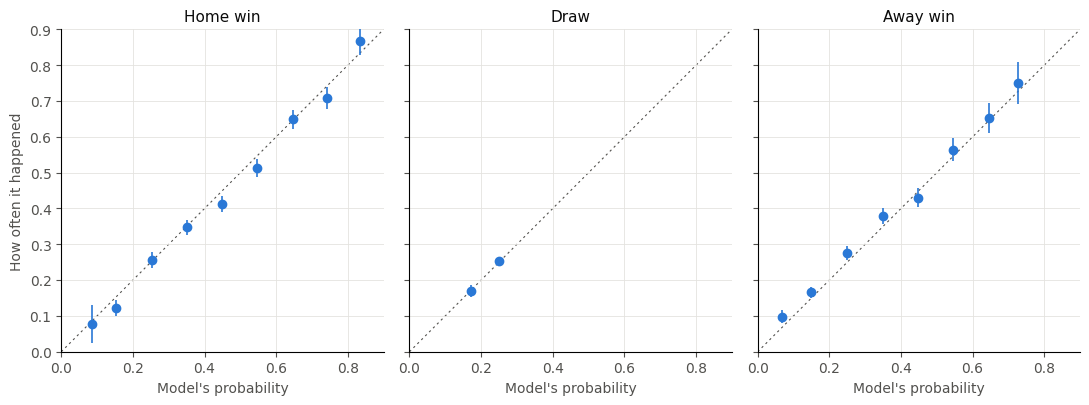

In [8]:
cal = result["calibration"]["model"]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, outcome, title in zip(axes, OUTCOMES, ["Home win", "Draw", "Away win"]):
    c = cal[(cal["outcome"] == outcome) & (cal["games"] >= 20)]
    ax.plot([0, 0.9], [0, 0.9], color=MUTED, linewidth=0.8, linestyle=(0, (2, 3)), zorder=1)
    ax.errorbar(c["predicted"], c["actual"], yerr=c["standard_error"], fmt="o", color="#2a78d6",
                ms=6, elinewidth=1.2, capsize=0, zorder=3)
    ax.set_title(title, color=INK, fontsize=11)
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 0.9)
    ax.set_aspect("equal")
    ax.set_xlabel("Model's probability", color=MUTED)
    ax.grid(color=RULE, linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("How often it happened", color=MUTED)
plt.tight_layout()
plt.show()

### The weights of the model that goes live

This model is trained on every finished Premier League match from 2002-03 to today, with the frozen settings, and milestone 4 will predict with it. The weights are on standardized features: each is the change in an outcome's score when that feature goes up by one standard deviation. They are sorted by how much they separate a home win from an away win.

Elastic net sets weak weights to exactly 0. The Elo difference and the Elo curve carry most of the signal. Shots on target come next.

In [9]:
final = train_final(table, settings)
w = weights(final, model_features(settings))
w.loc[(w["H"] - w["A"]).abs().sort_values(ascending=False).index].round(3)

,H,D,A
elo_diff,0.426,0.000,-0.192
elo_expected,0.009,0.000,-0.269
away_sota_10,0.042,0.000,-0.111
home_sotf_5,0.052,0.000,-0.078
away_sotf_10,-0.034,0.000,0.090
elo_sum,0.111,-0.048,0.000
home_sota_10,-0.054,0.000,0.033
home_sotf_10,0.000,0.000,-0.071
away_came_up,0.062,-0.010,0.000
home_ppg_10,-0.060,0.000,0.000
